# Khmer Handwriting Recognition  

## Preprocess the Synthetic Alphabet Images

In [6]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

SYNTH_DIR = Path("../../data/synthetic_alphabet")
READY_DIR = Path("../../data/3_ready/cnn_alphabet")
CHARTS_DIR = Path("../../results/charts/samples")
READY_DIR.mkdir(parents=True, exist_ok=True)
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(Path("../../src").resolve()))
from preprocess import IMG_HEIGHT, IMG_WIDTH, prepare_image

df = pd.read_parquet(SYNTH_DIR / "dataset.parquet")
print(f"rows: {len(df)}, classes: {df['text'].nunique()}, target size: {IMG_HEIGHT}x{IMG_WIDTH}")
df["split"].value_counts()

rows: 2640, classes: 33, target size: 32x32


split
train    1848
test      396
val       396
Name: count, dtype: int64

## Step 1: clean every image: OpenCV invert + Otsu-threshold + contour-crop + resize/pad

In [7]:
print("cleaning all images (this takes a minute)...")
df["cleaned"] = df["image"].apply(lambda png_bytes: prepare_image(png_bytes, IMG_HEIGHT, IMG_WIDTH))
print("done")

cleaning all images (this takes a minute)...
done


## Step 2: save the cleaned dataset so later notebooks don't re-run OpenCV every time

In [8]:
to_save = df[["text", "split", "category"]].copy()
to_save["cleaned"] = df["cleaned"].apply(lambda arr: arr.ravel())  # parquet needs 1D array values
to_save.to_parquet(READY_DIR / "cleaned_dataset.parquet")
print("Wrote:", READY_DIR / "cleaned_dataset.parquet")

Wrote: ..\..\data\3_ready\cnn_alphabet\cleaned_dataset.parquet


## Step 3: visual check, 12 cleaned samples

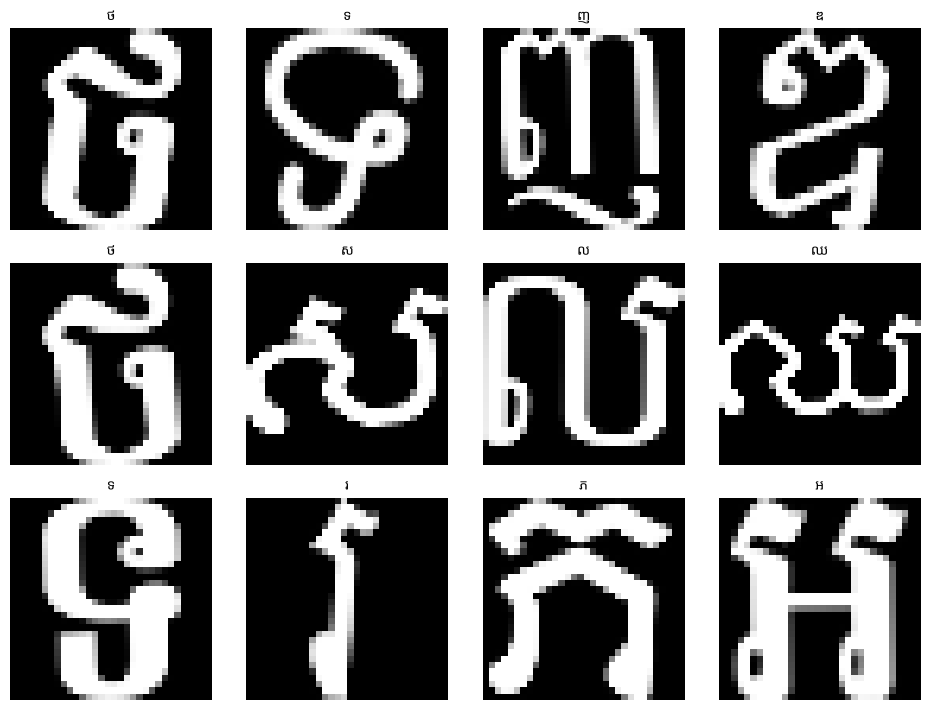

Wrote: ..\..\results\charts\samples\cleaned_sample_images.png


In [9]:
from plotting import khmer_font_prop

khmer_prop = khmer_font_prop()

sample_df = df.sample(n=12, random_state=0).reset_index(drop=True)
fig, axes = plt.subplots(3, 4, figsize=(4 * 2.4, 3 * 2.4))
axes = axes.ravel()
for ax, (_, row) in zip(axes, sample_df.iterrows()):
    ax.imshow(row["cleaned"], cmap="gray")
    ax.set_title(row["text"], fontsize=12, fontproperties=khmer_prop)
    ax.axis("off")
plt.tight_layout()
fig.savefig(CHARTS_DIR / "cleaned_sample_images.png", dpi=150)
plt.show()

print("Wrote:", CHARTS_DIR / "cleaned_sample_images.png")